# Phase 5 · Customer locations and a new branch

**Business question 3:** Where do customers come from, and where should a new branch open?

In this notebook we map where customers are, measure how well each state is served today, and rank the states as candidates for a new branch using criteria defined before looking at the results. Then we check whether the ranking holds when the criteria weigh differently, and we look for the city where a branch would be closest to its customers.

**Input:** the SQLite database `olist.db`. The queries are in the `sql/` folder.

**Outputs** in `data/processed/`:

| File | Content |
|---|---|
| `state_scores.csv` | Demand, service indicators and branch score of each state |
| `city_summary.csv` | Customers, revenue and location of each city |

## 1. Libraries, paths, chart style and SQL helper

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

PROCESSED = Path("..") / "data" / "processed"
DATABASE = PROCESSED / "olist.db"
SQL_DIR = Path("..") / "sql"
FIGURES = Path("..") / "reports" / "figures"
pd.set_option("display.max_columns", 40)

BLUE = "#2a78d6"
ORANGE = "#eb6834"
GRAY = "#898781"
LIGHT_GRAY = "#c3c2b7"
INK = "#0b0b0b"
SECONDARY_INK = "#52514e"
GRID = "#e1e0d9"
SEQUENTIAL_BLUES = LinearSegmentedColormap.from_list("sequential_blues", ["#cde2fb", "#104281"])

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.edgecolor": LIGHT_GRAY,
    "axes.labelcolor": SECONDARY_INK,
    "axes.titlecolor": INK,
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
    "axes.titlepad": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": SECONDARY_INK,
    "ytick.color": SECONDARY_INK,
    "xtick.major.size": 0,
    "ytick.major.size": 0,
    "legend.frameon": False,
})

PERIOD = {"start": "2017-01-01", "end": "2018-09-01"}
EARTH_RADIUS_KM = 6371


def run_sql(name, show=True, **params):
    # Reads sql/<name>.sql, prints it and returns the result as a DataFrame
    query = (SQL_DIR / f"{name}.sql").read_text(encoding="utf-8")
    if show:
        print(query)
    with closing(sqlite3.connect(DATABASE)) as connection:
        return pd.read_sql_query(query, connection, params=params)


def run_sql_script(name, show=True):
    # Runs a file with several statements, such as the creation of a view
    script = (SQL_DIR / f"{name}.sql").read_text(encoding="utf-8")
    if show:
        print(script)
    with closing(sqlite3.connect(DATABASE)) as connection:
        connection.executescript(script)


def haversine_km(lat1, lng1, lat2, lng2):
    # Great-circle distance between two points on the Earth's surface, in kilometers
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(a))

## 2. What a new branch means here, and how we will choose it

Olist has no warehouses of its own: each seller ships from its own location, and 59.5% of the sellers are in the state of São Paulo (Phase 2). In this context, a new branch is a regional point from which products can be shipped closer to the customers who are far from where products ship today. For the agricultural machinery business it is literally a new store.

We define the criteria **before** looking at the results, so that the recommendation comes from the data and not the other way around:

| Criterion | Measured with | Weight | Why |
|---|---|---|---|
| Demand | number of customers in the state | 50% | a branch needs enough customers to pay off |
| Service gap | average of three indicators: average freight per order, median delivery days and share of late deliveries | 50% | the worse a state is served today, the more a nearby branch can improve it |

Each indicator is turned into a percentile between 0 and 1 across the 27 states, so that indicators measured in different units can be combined. We use percentiles instead of raw values because São Paulo alone has 39,058 customers, more than three times the next state, and with raw values it would dominate any score.

**Score = 0.5 × demand percentile + 0.5 × service gap percentile.** At the end we test other weights to see whether the recommendation depends on this choice.

## 3. Where the customers are

We recreate the view from Phase 2 that adds the region to each order, and summarize the demand and service indicators of each state in a single query.

In [2]:
run_sql_script("orders_with_region_view", show=False)
states = run_sql("state_summary", **PERIOD).set_index("customer_state")
states["customers_pct"] = states["customers"] / states["customers"].sum() * 100
states[["region", "customers", "customers_pct", "orders", "revenue", "avg_ticket"]].head(10).round(1)

-- Demand and service indicators by customer state: customers, orders, revenue,
-- average freight, share of late deliveries and median delivery days.
-- The median is computed with window functions because SQLite has no MEDIAN function.
WITH period_orders AS (
    SELECT *
    FROM orders_with_region
    WHERE purchase_date >= :start
      AND purchase_date < :end
),
ranked AS (
    SELECT
        customer_state,
        delivery_days,
        ROW_NUMBER() OVER (PARTITION BY customer_state ORDER BY delivery_days) AS position,
        COUNT(*) OVER (PARTITION BY customer_state) AS state_orders
    FROM period_orders
),
medians AS (
    SELECT
        customer_state,
        AVG(delivery_days) AS median_delivery_days
    FROM ranked
    WHERE position IN ((state_orders + 1) / 2, (state_orders + 2) / 2)
    GROUP BY customer_state
)
SELECT
    p.customer_state,
    p.region,
    COUNT(DISTINCT p.customer_unique_id) AS customers,
    COUNT(*) AS orders,
    SUM(p.revenue) AS revenue,
    

,region,customers,customers_pct,orders,revenue,avg_ticket
customer_state,,,,,,
SP,Southeast,39058,41.9,40399,5054517.0,125.1
RJ,Southeast,11879,12.8,12310,1751433.8,142.3
MG,Southeast,10969,11.8,11319,1548206.9,136.8
RS,South,5150,5.5,5327,726194.9,136.3
PR,South,4750,5.1,4903,664048.0,135.4
SC,South,3441,3.7,3537,504774.1,142.7
BA,Northeast,3155,3.4,3253,493339.3,151.7
DF,Central-West,2013,2.2,2074,295454.6,142.5
ES,Southeast,1925,2.1,1992,267783.7,134.4


To see the customers on a map we place every order at the coordinates of its zip code prefix and count how many orders fall in each hexagon. The color scale is logarithmic, because the orders in São Paulo would otherwise hide the rest of the country.

-- Location of every order, from the customer's zip code prefix, for the customer map
SELECT
    o.order_id,
    o.customer_state,
    g.lat,
    g.lng
FROM orders AS o
JOIN geolocation AS g
    ON g.zip_prefix = o.customer_zip_prefix
WHERE o.purchase_date >= :start
  AND o.purchase_date < :end;



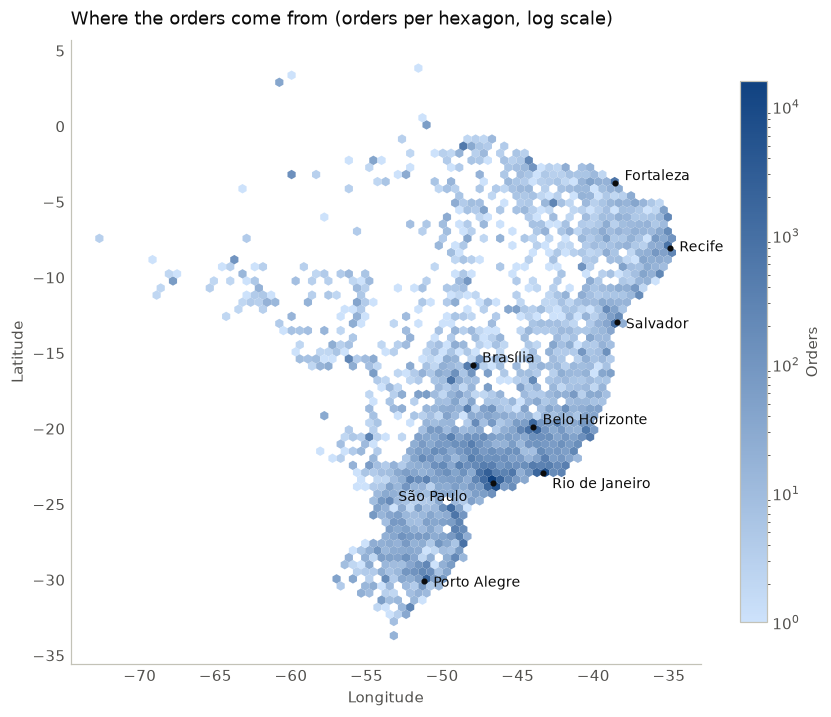

In [3]:
locations = run_sql("order_locations", **PERIOD)
cities = run_sql("city_summary", show=False, **PERIOD)

# Capitals labeled on the map, with the offset of each label in points
LABELS = {
    "sao paulo": ("São Paulo", (-62, -12)),
    "rio de janeiro": ("Rio de Janeiro", (6, -10)),
    "belo horizonte": ("Belo Horizonte", (6, 2)),
    "brasilia": ("Brasília", (6, 2)),
    "porto alegre": ("Porto Alegre", (6, -4)),
    "salvador": ("Salvador", (6, -4)),
    "recife": ("Recife", (6, -2)),
    "fortaleza": ("Fortaleza", (6, 2)),
}

fig, ax = plt.subplots(figsize=(8, 8.5))
hexagons = ax.hexbin(locations["lng"], locations["lat"], gridsize=70, bins="log",
                     cmap=SEQUENTIAL_BLUES, mincnt=1, linewidths=0)
largest_city = cities.sort_values("customers", ascending=False).drop_duplicates("customer_city").set_index("customer_city")
for city, (label, offset) in LABELS.items():
    ax.plot(largest_city.loc[city, "lng"], largest_city.loc[city, "lat"], "o", color=INK, markersize=3)
    ax.annotate(label, (largest_city.loc[city, "lng"], largest_city.loc[city, "lat"]), xytext=offset,
                textcoords="offset points", color=INK, fontsize=9)
ax.set_aspect("equal")
ax.set_title("Where the orders come from (orders per hexagon, log scale)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(False)
fig.colorbar(hexagons, ax=ax, shrink=0.6, label="Orders")
fig.tight_layout()
fig.savefig(FIGURES / "05_customer_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
cities.head(10).round(1)

,customer_city,customer_state,customers,orders,revenue,lat,lng,share_of_state_customers_pct
0,sao paulo,SP,14500,15014,1856066.9,-23.6,-46.6,37.1
1,rio de janeiro,RJ,6336,6574,949362.8,-22.9,-43.3,53.3
2,belo horizonte,MG,2597,2687,344845.8,-19.9,-44.0,23.7
3,brasilia,DF,2007,2065,294771.0,-15.8,-48.0,99.7
4,curitiba,PR,1429,1483,205581.6,-25.5,-49.3,30.1
5,campinas,SP,1357,1400,184206.3,-22.9,-47.1,3.5
6,porto alegre,RS,1289,1339,182004.2,-30.0,-51.2,25.0
7,salvador,BA,1154,1188,173273.0,-13.0,-38.5,36.6
8,guarulhos,SP,1109,1142,138817.3,-23.4,-46.5,2.8
9,sao bernardo do campo,SP,878,908,102411.4,-23.7,-46.6,2.2


Customers are concentrated in the Southeast. The state of São Paulo alone has 41.9% of them, and the city of São Paulo has 14,500 customers, more than the whole Northeast region (8,786). On the map, orders follow the coast and the South and Southeast, while the interior of the North has very few.

The largest cities are São Paulo, Rio de Janeiro, Belo Horizonte and Brasília. Salvador, in eighth place with 1,154 customers, is the first city outside the South, the Southeast and the capital district.

## 4. How well each state is served today

For every item sold we measure the distance between the customer and the seller who shipped it. The query joins the geolocation table twice, once for each side, and Python computes the great-circle distance between the two points. Then we take the median distance of each state's orders.

In [5]:
shipping = run_sql("shipping_coordinates", **PERIOD)
shipping["distance_km"] = haversine_km(shipping["customer_lat"], shipping["customer_lng"],
                                       shipping["seller_lat"], shipping["seller_lng"])

# One distance per order (the average of its items), then the median of each state
order_distance = shipping.groupby(["order_id", "customer_state"])["distance_km"].mean().reset_index()
states["median_distance_km"] = order_distance.groupby("customer_state")["distance_km"].median()

service_columns = ["region", "customers", "median_distance_km", "avg_freight", "median_delivery_days", "late_pct"]
states[service_columns].sort_values("median_distance_km").round(1)

-- Customer and seller coordinates for every item sold, to measure shipping distances.
-- The geolocation table is joined twice: once for the customer's zip code prefix
-- and once for the seller's.
SELECT
    i.order_id,
    o.customer_state,
    customer_geo.lat AS customer_lat,
    customer_geo.lng AS customer_lng,
    seller_geo.lat AS seller_lat,
    seller_geo.lng AS seller_lng
FROM items AS i
JOIN orders AS o
    ON o.order_id = i.order_id
JOIN geolocation AS customer_geo
    ON customer_geo.zip_prefix = o.customer_zip_prefix
JOIN geolocation AS seller_geo
    ON seller_geo.zip_prefix = i.seller_zip_prefix
WHERE o.purchase_date >= :start
  AND o.purchase_date < :end;



,region,customers,median_distance_km,avg_freight,median_delivery_days,late_pct
customer_state,,,,,,
SP,Southeast,39058,163.8,17.3,7.0,4.5
RJ,Southeast,11879,395.5,24.0,12.0,12.1
PR,South,4750,426.7,23.5,10.0,4.1
MG,Southeast,10969,490.5,23.5,10.0,4.6
SC,South,3441,528.1,24.8,13.0,8.2
ES,Southeast,1925,761.9,24.5,14.0,10.7
GO,Central-West,1889,804.0,26.3,14.0,6.6
RS,South,5150,855.8,24.8,13.0,6.1
MS,Central-West,681,861.4,27.0,14.0,9.7


Rank correlation between distance and delivery days across states: 0.89


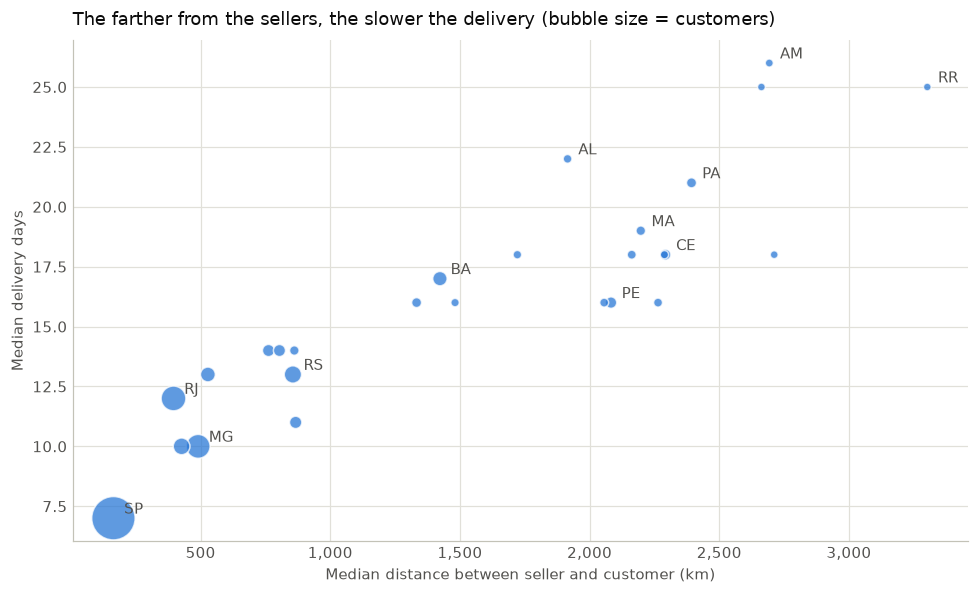

In [6]:
correlation = states["median_distance_km"].corr(states["median_delivery_days"], method="spearman")
print(f"Rank correlation between distance and delivery days across states: {correlation:.2f}")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(states["median_distance_km"], states["median_delivery_days"], s=states["customers"] / 50 + 25,
           color=BLUE, alpha=0.75, edgecolor="white", linewidth=1)
for state in ["SP", "RJ", "MG", "RS", "BA", "PE", "CE", "MA", "PA", "AL", "AM", "RR"]:
    ax.annotate(state, (states.loc[state, "median_distance_km"], states.loc[state, "median_delivery_days"]),
                xytext=(7, 3), textcoords="offset points", color=SECONDARY_INK)
ax.set_title("The farther from the sellers, the slower the delivery (bubble size = customers)")
ax.set_xlabel("Median distance between seller and customer (km)")
ax.set_ylabel("Median delivery days")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
fig.tight_layout()
fig.savefig(FIGURES / "05_distance_vs_delivery.png", dpi=150, bbox_inches="tight")
plt.show()

The farther customers are from the sellers, the slower their deliveries: across states, the rank correlation between median distance and median delivery days is 0.89. São Paulo receives its orders in 7 days, from a median distance of 164 km, while Amazonas, Amapá and Roraima wait 25 days or more, from 2,600 km or farther. Freight follows the same pattern, from R$ 17.30 per order in São Paulo to almost R$ 49 in Paraíba and Roraima.

Late deliveries tell a different story. Alagoas (21.5%), Maranhão (17.5%) and Sergipe (15.4%) have the most late orders, and Rio de Janeiro reaches 12.1% even though it is only 396 km from the sellers. Meanwhile Amazonas takes 26 days but only 2.8% of its orders arrive late. The reason is that "late" is measured against the promised date, and the promise for distant states already includes the long trip. A late order is a broken promise, not necessarily a slow delivery.

## 5. Ranking the states

We now apply the criteria defined in section 2. Each indicator becomes a percentile across the 27 states; for the service gap, a higher percentile means worse service today.

In [7]:
DEMAND_WEIGHT = 0.5
SERVICE_INDICATORS = ["avg_freight", "median_delivery_days", "late_pct"]

states["demand_score"] = states["customers"].rank(pct=True)
states["service_gap_score"] = states[SERVICE_INDICATORS].rank(pct=True).mean(axis=1)
states["score"] = DEMAND_WEIGHT * states["demand_score"] + (1 - DEMAND_WEIGHT) * states["service_gap_score"]
states["rank"] = states["score"].rank(ascending=False, method="min").astype(int)

ranking = states.sort_values("score", ascending=False)
ranking[["region", "customers", "avg_freight", "median_delivery_days", "late_pct",
         "demand_score", "service_gap_score", "score"]].head(10).round(2)

,region,customers,avg_freight,median_delivery_days,late_pct,demand_score,service_gap_score,score
customer_state,,,,,,,,
BA,Northeast,3155,29.97,17.0,12.17,0.78,0.59,0.69
MA,Northeast,696,42.78,19.0,17.53,0.48,0.86,0.67
RJ,Southeast,11879,23.96,12.0,12.14,0.96,0.37,0.67
PA,North,918,39.66,21.0,11.25,0.56,0.74,0.65
CE,Northeast,1252,36.48,18.0,13.83,0.59,0.69,0.64
PB,Northeast,503,48.89,18.0,10.47,0.41,0.78,0.59
RS,South,5150,24.81,13.0,6.10,0.89,0.29,0.59
SC,South,3441,24.84,13.0,8.23,0.81,0.33,0.57
PE,Northeast,1545,35.78,16.0,9.64,0.63,0.49,0.56


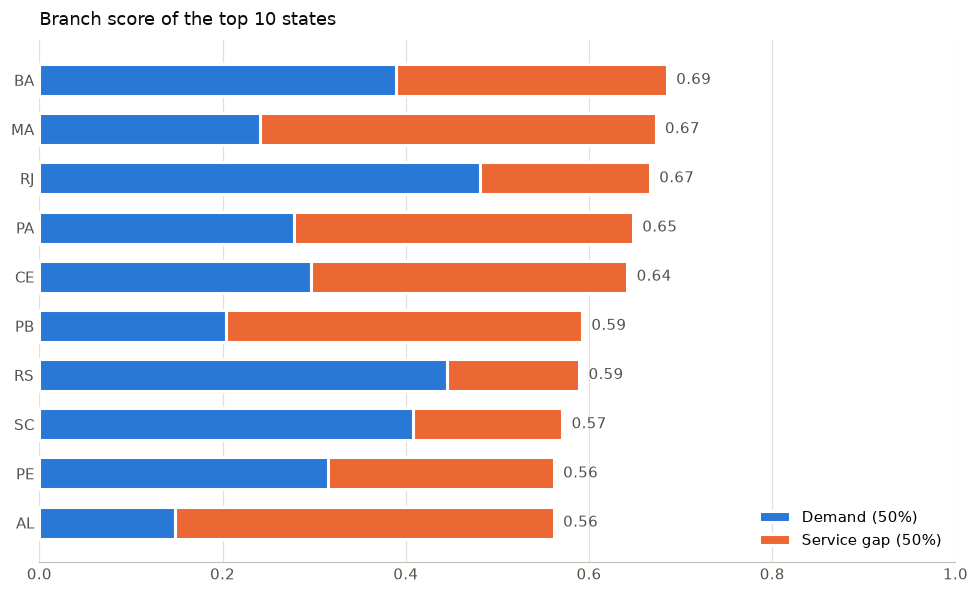

In [8]:
top_10 = ranking.head(10).iloc[::-1]
demand_part = DEMAND_WEIGHT * top_10["demand_score"]
service_part = (1 - DEMAND_WEIGHT) * top_10["service_gap_score"]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top_10.index, demand_part, color=BLUE, height=0.65, edgecolor="white", linewidth=2,
        label="Demand (50%)")
ax.barh(top_10.index, service_part, left=demand_part, color=ORANGE, height=0.65, edgecolor="white",
        linewidth=2, label="Service gap (50%)")
for row, (state, score) in enumerate(top_10["score"].items()):
    ax.text(score + 0.01, row, f"{score:.2f}", va="center", color=SECONDARY_INK)
ax.set_xlim(0, 1)
ax.set_title("Branch score of the top 10 states")
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "05_branch_scores.png", dpi=150, bbox_inches="tight")
plt.show()

Bahia comes first (0.69), followed by Maranhão (0.67), Rio de Janeiro (0.67), Pará (0.65) and Ceará (0.64). The chart shows that they reach the top for different reasons:

- Rio de Janeiro scores mostly on demand: it is the second largest market (11,879 customers), and its service gap is moderate, driven by late deliveries (12.1%).
- Maranhão and Pará score mostly on the service gap: they are small markets (696 and 918 customers) and among the worst served, with median deliveries of 19 and 21 days.
- Bahia combines both. It is the largest market outside the South and Southeast (3,155 customers), and its customers wait 17 days for their orders, 12.2% of which arrive late.

## 6. Does the ranking depend on the weights?

The 50/50 split between demand and service gap is a choice. To check how much the result depends on it, we repeat the ranking giving 70% of the weight to demand and then only 30%, and compare the position of each state in the three scenarios. A state that stays near the top in all of them is a robust candidate.

In [9]:
scenarios = {"rank_70pct_demand": 0.7, "rank_50pct_demand_base": 0.5, "rank_30pct_demand": 0.3}
scenario_ranks = pd.DataFrame({
    name: (weight * states["demand_score"] + (1 - weight) * states["service_gap_score"])
    .rank(ascending=False, method="min")
    for name, weight in scenarios.items()
}).astype(int)
scenario_ranks["average_rank"] = scenario_ranks.mean(axis=1)
scenario_ranks.sort_values("average_rank").head(10).round(1)

,rank_70pct_demand,rank_50pct_demand_base,rank_30pct_demand,average_rank
customer_state,,,,
BA,3,1,6,3.3
RJ,1,3,10,4.7
MA,11,2,1,4.7
PA,10,4,2,5.3
CE,8,5,5,6.0
PB,15,6,4,8.3
RS,4,7,16,9.0
SC,6,8,14,9.3
AL,18,9,3,10.0


The ranking does depend on the weights, and that is a result in itself. When demand weighs 70%, the large markets rise: Rio de Janeiro takes first place and Rio Grande do Sul fourth. When the service gap weighs 70%, the small and poorly served states rise: Maranhão first, Pará second and Alagoas third.

Bahia is the most robust candidate: it has the best average position (3.3) and never falls below sixth place. Ceará is also consistent, between fifth and eighth. Rio de Janeiro and Maranhão are strong candidates only under one view of the business.

## 7. From the state to the city

A branch is opened in a city, not in a state. For the top five states we look at the city with the most customers and how much of the state's demand it concentrates.

In [10]:
top_states = ranking.head(5).index
main_cities = (
    cities[cities["customer_state"].isin(top_states)]
    .sort_values("customers", ascending=False)
    .drop_duplicates("customer_state")
    .set_index("customer_state")
    .loc[top_states, ["customer_city", "customers", "share_of_state_customers_pct", "revenue"]]
)
main_cities.round(1)

,customer_city,customers,share_of_state_customers_pct,revenue
customer_state,,,,
BA,salvador,1154,36.6,173273.0
MA,sao luis,325,46.7,49674.4
RJ,rio de janeiro,6336,53.3,949362.8
PA,belem,418,45.5,78002.8
CE,fortaleza,605,48.3,92309.8


If several of the top states belong to the same region, a single branch could serve all of them. To choose its location we compare the main city of each state in that region by the **average distance to all of the region's orders**: the lower it is, the closer the branch would be to its customers.

In [11]:
top_region = ranking.head(5)["region"].value_counts().idxmax()
region_states = states.index[states["region"] == top_region]
region_orders = locations[locations["customer_state"].isin(region_states)]

candidates = (
    cities[cities["customer_state"].isin(region_states)]
    .sort_values("customers", ascending=False)
    .drop_duplicates("customer_state")
)
candidates["avg_distance_to_region_orders_km"] = [
    haversine_km(city["lat"], city["lng"], region_orders["lat"], region_orders["lng"]).mean()
    for _, city in candidates.iterrows()
]
print(f"Region with the most states in the top five: {top_region} ({len(region_orders):,} orders)")
candidates.sort_values("avg_distance_to_region_orders_km")[
    ["customer_city", "customer_state", "customers", "avg_distance_to_region_orders_km"]
].round(0)

Region with the most states in the top five: Northeast (8,987 orders)


,customer_city,customer_state,customers,avg_distance_to_region_orders_km
63,aracaju,SE,208,520.0
54,maceio,AL,232,539.0
18,recife,PE,567,573.0
7,salvador,BA,1154,576.0
53,joao pessoa,PB,234,604.0
66,natal,RN,197,646.0
16,fortaleza,CE,605,693.0
45,teresina,PI,260,757.0
32,sao luis,MA,325,1002.0


Salvador, the capital of Bahia, concentrates 36.6% of the state's customers (1,154) and is the largest city of the Northeast by number of customers.

Three of the top five states are in the Northeast (Bahia, Maranhão and Ceará), so a single regional branch could serve them. Among the region's main cities, the most central is Aracaju, 520 km on average from the Northeast's orders, followed by Maceió (539 km), Recife (573 km) and Salvador (576 km). Salvador is only 56 km farther than Aracaju on average but has more than five times as many customers (1,154 against 208), so it combines a central position with the largest local market. Recife is an alternative with a similar distance and about half the customers. São Luís, the capital of Maranhão, would be a poor choice for a regional branch: it sits at the western edge of the region, 1,002 km on average from its orders.

## 8. Saving

In [12]:
outputs = {
    "state_scores.csv": ranking.reset_index(),
    "city_summary.csv": cities,
}
for name, table in outputs.items():
    table.to_csv(PROCESSED / name, index=False, float_format="%.4f")
    print(f"{name:<18} {len(table):>6,} rows")

state_scores.csv       27 rows
city_summary.csv    4,270 rows


## Answer to business question 3

**Business question.** Where do customers come from, and where should a new branch open?

**Analysis.** We located every order through its zip code prefix, measured each state's demand and the service it receives today (freight, delivery time, late deliveries and distance to the sellers), and ranked the 27 states with criteria defined before looking at the results: 50% demand and 50% service gap. We tested the ranking with other weights and compared the main cities of the leading region by their average distance to the region's orders.

**Evidence.**

- Customers are concentrated in the Southeast: the state of São Paulo has 41.9% of them, and the city of São Paulo has more customers (14,500) than the whole Northeast (8,786).
- The farther from the sellers, the slower the delivery (rank correlation of 0.89 between distance and delivery days): 7 days in São Paulo, 17 in Bahia and 25 or more in Amazonas, Amapá and Roraima.
- Bahia leads the ranking (0.69) and is the most robust candidate when the weights change (average position 3.3). Three of the top five states are in the Northeast.
- Within the Northeast, Salvador is 576 km on average from the region's orders, close to the most central city (Aracaju, 520 km), and it has the region's largest customer base (1,154).

**Insight.** Demand and service quality pull in opposite directions: the largest markets are the best served, and the worst served markets are small. Bahia and the Northeast are where both criteria meet: a meaningful market that waits more than two weeks for its orders (17 days in Bahia) and pays about 70% more freight than São Paulo (R$ 30 against R$ 17). Rio de Janeiro ranks high because of its size, but its problem is late deliveries rather than distance, so a branch is not the obvious fix there.

**Recommendation.**

1. If a new branch is opened, Salvador is the best-supported location: it serves the largest market of the most promising region and sits close to the center of the Northeast's demand.
2. Before deciding, the business should state explicitly how much it values growing where customers already are (demand) against improving service where it is poor, because the ranking changes with that choice.
3. In Rio de Janeiro, investigate the causes of the late deliveries (carriers, delivery promises) before considering a branch.

**Application to the machinery business.** The same criteria translate directly to towns and rural areas. Demand becomes the number of customers or machines sold in each area, and the service gap becomes the distance and travel time from the current store, the cost of transport and the response time for spare parts and repairs. With the business's sales data, this notebook ranks the areas in the same way, and the weights should be agreed with the owners before looking at the results. A branch also has costs (rent, staff, stock) that are not in the sales data, so the ranking produces a shortlist, not the final decision.

**Limitations.** Olist sellers ship from their own locations, so a branch is a simplification of how the marketplace works. The analysis leaves out the cost of opening a branch, the location of competitors and population data, and its ranking depends on the chosen weights. Distances are straight lines between zip code areas, not road distances.